+ матрицы регулярные
+ работаем с нулевым кодовым словом
+ $r = \frac{1}{2} = \frac{k}{n}$ - design ratio, или скорость как нам Алексей с Павлом говорили
+ $p$ - вероятность ошибки
+ $l = l_\text{avg} = L(1)$ - количество связей у variable node
+ $n_0 = r_\text{avg} = R(1)$ - количество связей у check node

+ $\rho(x) = \frac{R'(x)}{R'(1)} = \sum_{i = 1}^{r_{max}}\rho_i x^{i - 1} = (x)^{n_0 - 1}$
+ $t$ - threshold, некоторое достаточное количество check node указывающих на ошибку, обычно хотя бы больше половины
+ $p_\text{c.n.} = \frac{1 - \rho(1 - 2p)}{2}$ - вероятность того, что check node указывает на ошибку
+ $p_\text{v.n.} = \sum_{i = t}^l \binom{l}{i} p_\text{c.n.}^i (1 - p_\text{c.n.})^{l - i}$ - вероятность того, что variable node ошибочный

Идея алгоритма density evolution состоит в том, чтобы мы рассчитали вероятность ошибки в variable node используя вероятность ошибки в канале, а в последующих итерациях мы подставляли вероятность ошибки в variable node из предыдущей итерации и снова считали

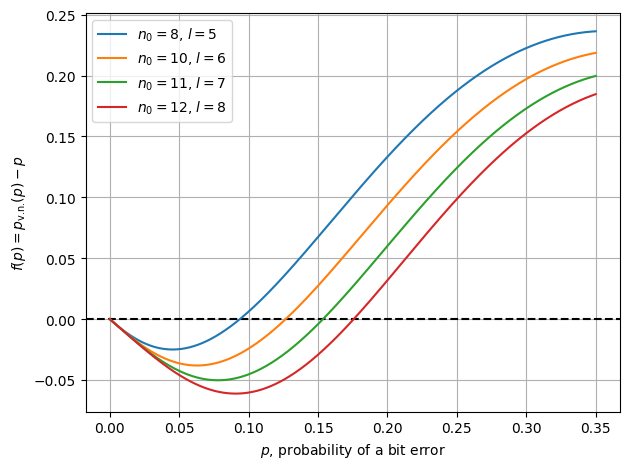

In [1]:
import sys
import os

import numpy as np
import matplotlib.pyplot as plt
from DE import density_evolution

plt.axhline(0, color='black', linestyle='--')
plt.grid()
density_evolution(np.loadtxt('../data/H_matrix/H5_1000x1500.txt', delimiter=','))
density_evolution(np.loadtxt('../data/H_matrix/H6_1000x1500.txt', delimiter=','))
density_evolution(np.loadtxt('../data/H_matrix/H7_1000x1500.txt', delimiter=','))
density_evolution(np.loadtxt('../data/H_matrix/H8_1000x1500.txt', delimiter=','))
plt.xlabel('$p$, probability of a bit error')
plt.ylabel('$f(p) = p_\\text{v.n.}(p) - p$')
plt.legend()
plt.tight_layout()
plt.savefig('de.pdf')

In [ ]:
import numpy
from scipy.special import comb

def compute_q(p, n0):
    return (1 - (1 - 2 * p)**(n0 - 1)) / 2

def compute_error_probability(i, l, k, th, q, x):
    error_prob = 0
    for j in range(th, k + 1):
        binom_coeff = comb(l, j)
        term = binom_coeff * (q**i) * ((x - q)**(l - j))
        error_prob += term
    return error_prob

def density_evolution(p, n0, l, k, th, x, max_iterations):
    error_probabilities = []
    for i in range(1, max_iterations + 1):
        q = compute_q(p, n0)
        P_e = compute_error_probability(i, l, k, th, q, x)
        error_probabilities.append(P_e)
        if i > 1 and abs(error_probabilities[-1] - error_probabilities[-2]) < 1e-6:
            break
    return error_probabilities

p = 0.1
n0 = 5
l = 10
k = 5
th = 3
x = 1.0
max_iterations = 100

error_probs = density_evolution(p, n0, l, k, th, x, max_iterations)
print("Probabilities of error per iteration:", error_probs)